# Text Classification
## Natural Language Processing
### Task Type: Ontology Classification
Descrption: The goal is to predict the ontology class (among 14 classes) of a given text.

#### Step 1: Reading the dataset

In [ ]:
%pip install -U datasets
!pip install tensorflow nltk

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from google.colab import userdata

Tokens
hf_token = userdata.get('HF_TOKEN')

In [ ]:
# Imports
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from typing import Dict
from nltk.util import ngrams
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report,  confusion_matrix
from datasets import load_dataset, concatenate_datasets, Dataset, DatasetDict
from tensorflow.keras.layers import TextVectorization, Embedding, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import TextVectorization, Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.models import Sequential
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /home/kpch/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/kpch/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /home/kpch/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/kpch/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [40]:
# https://huggingface.co/datasets/fancyzhx/dbpedia_14
ds = load_dataset("fancyzhx/dbpedia_14")

In [41]:
original_len = len(ds['train']) + len(ds['test'])
print("The whole dataset is under the 'train' and 'test' labels, we will combine them into one and later split into 'train', 'test' and 'validation' while trying to maintain class balance.")
print("Train entries: ", len(ds['train']))
print("Test entries: ", len(ds['test']))
print("Total entries: ", original_len)

# percent of split
print("\nTrain-test split")
print("Train split percent: ", len(ds['train'])/original_len)
print("Test split percent: ", len(ds['test'])/original_len)


The whole dataset is under the 'train' and 'test' labels, we will combine them into one and later split into 'train', 'test' and 'validation' while trying to maintain class balance.
Train entries:  560000
Test entries:  70000
Total entries:  630000

Train-test split
Train split percent:  0.8888888888888888
Test split percent:  0.1111111111111111


In [42]:
# Describe the datatypes of the original dataset
ds['train'].info.features

{'label': ClassLabel(names=['Company', 'EducationalInstitution', 'Artist', 'Athlete', 'OfficeHolder', 'MeanOfTransportation', 'Building', 'NaturalPlace', 'Village', 'Animal', 'Plant', 'Album', 'Film', 'WrittenWork'], id=None),
 'title': Value(dtype='string', id=None),
 'content': Value(dtype='string', id=None)}

In [43]:
ds['test'].info.features

{'label': ClassLabel(names=['Company', 'EducationalInstitution', 'Artist', 'Athlete', 'OfficeHolder', 'MeanOfTransportation', 'Building', 'NaturalPlace', 'Village', 'Animal', 'Plant', 'Album', 'Film', 'WrittenWork'], id=None),
 'title': Value(dtype='string', id=None),
 'content': Value(dtype='string', id=None)}

In [44]:
ds['train'][0]

{'label': 0,
 'title': 'E. D. Abbott Ltd',
 'content': ' Abbott of Farnham E D Abbott Limited was a British coachbuilding business based in Farnham Surrey trading under that name from 1929. A major part of their output was under sub-contract to motor vehicle manufacturers. Their business closed in 1972.'}

In [45]:
ds['test'][-1]

{'label': 13,
 'title': 'The Prophecy (novel)',
 'content': ' The Prophecy is the fifth novel by New York Times bestselling author Chris Kuzneski. Published in October 2009 by Penguin UK the action thriller follows the adventures of Jonathon Payne and David D.J. Jones as they try to decipher a newly discovered manuscript written by Nostradamus. The book peaked at #4 on the British fiction list and stayed on the bestseller list for several weeks. Putnam released the American hardcover version in July 2010.'}

In [46]:
ontology_classes = ds['train'].features['label'].names
for i in range(len(ontology_classes)):
  print(i, ontology_classes[i])

0 Company
1 EducationalInstitution
2 Artist
3 Athlete
4 OfficeHolder
5 MeanOfTransportation
6 Building
7 NaturalPlace
8 Village
9 Animal
10 Plant
11 Album
12 Film
13 WrittenWork


In [47]:
complete_ds = concatenate_datasets([ds['train'], ds['test']])
print(complete_ds.info.features)
complete_ds[-1]

{'label': ClassLabel(names=['Company', 'EducationalInstitution', 'Artist', 'Athlete', 'OfficeHolder', 'MeanOfTransportation', 'Building', 'NaturalPlace', 'Village', 'Animal', 'Plant', 'Album', 'Film', 'WrittenWork'], id=None), 'title': Value(dtype='string', id=None), 'content': Value(dtype='string', id=None)}


{'label': 13,
 'title': 'The Prophecy (novel)',
 'content': ' The Prophecy is the fifth novel by New York Times bestselling author Chris Kuzneski. Published in October 2009 by Penguin UK the action thriller follows the adventures of Jonathon Payne and David D.J. Jones as they try to decipher a newly discovered manuscript written by Nostradamus. The book peaked at #4 on the British fiction list and stayed on the bestseller list for several weeks. Putnam released the American hardcover version in July 2010.'}

Word Count Statistics:
count    630000.000000
mean         46.134148
std          22.457486
min           1.000000
25%          27.000000
50%          46.000000
75%          65.000000
max        1484.000000
Name: word_count, dtype: float64

Label Distribution:
    label  count
0       0  45000
1       1  45000
2       2  45000
3       3  45000
4       4  45000
5       5  45000
6       6  45000
7       7  45000
8       8  45000
9       9  45000
10     10  45000
11     11  45000
12     12  45000
13     13  45000


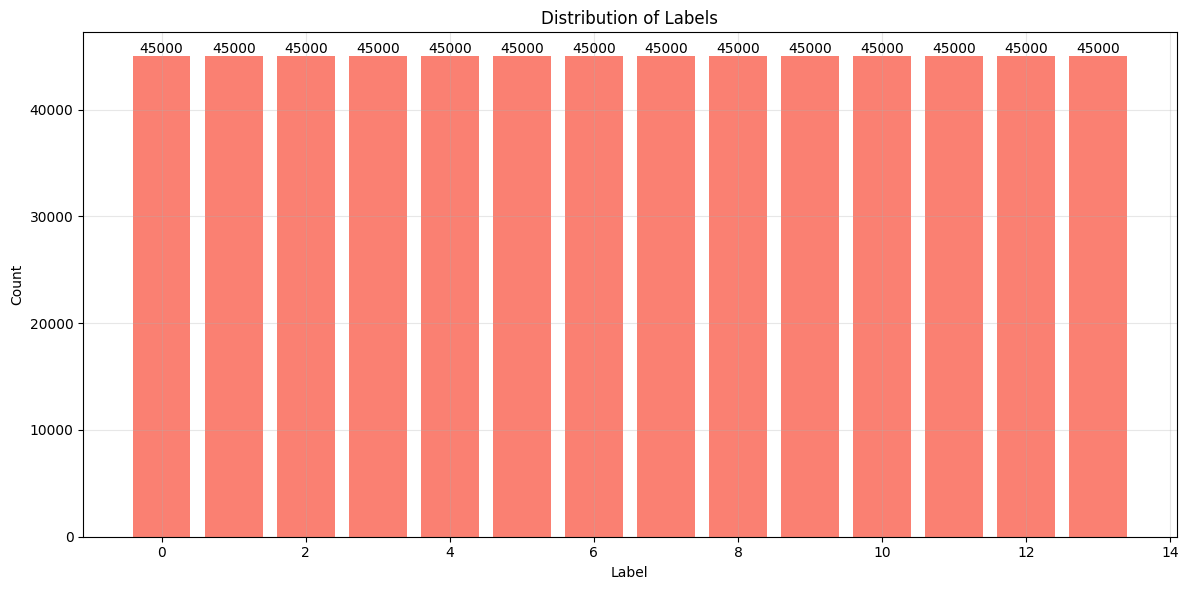

In [48]:
# Small Analysis

# Convert to pandas DataFrame for easier analysis
df = complete_ds.to_pandas()

# 1. Word Count Analysis
def count_words(text):
    return len(str(text).split())

df['word_count'] = df['content'].apply(count_words)

# Summary statistics
word_count_stats = df['word_count'].describe()
print("Word Count Statistics:")
print(word_count_stats)

# 2. Label Distribution Analysis
label_counts = df['label'].value_counts().sort_index()

# If we have class names (assuming they're available in ds.features['label'].names)
try:
    class_names = ds.features['label'].names
    label_names = [class_names[i] for i in label_counts.index]
    label_df = pd.DataFrame({
        'label': label_counts.index,
        'label_name': label_names,
        'count': label_counts.values
    })
except:
    label_df = pd.DataFrame({
        'label': label_counts.index,
        'count': label_counts.values
    })

print("\nLabel Distribution:")
print(label_df)

# Plot label distribution
plt.figure(figsize=(12, 6))
if 'label_name' in label_df.columns:
    bars = plt.bar(label_df['label_name'], label_df['count'], color='salmon')
    plt.xticks(rotation=45, ha='right')
else:
    bars = plt.bar(label_df['label'], label_df['count'], color='salmon')

plt.title('Distribution of Labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.grid(True, alpha=0.3)

# Add count labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom')

plt.tight_layout()
plt.show()

Interesting Observation:
- The creators of the dataset have clean it from terms like '\n', '\t', etc
- The 'content' has an average of 46.134148 words
- The classes are balanced

Reducing the total number of entries to ease the model training later on. Maintaing class balance by using `stratify=limited_df['label']`

In [49]:
# First limit each class to 10,000 samples (or less if class has fewer samples)
max_samples_per_class = 10000
limited_dfs = []
for label in df['label'].unique():
    class_df = df[df['label'] == label]
    limited_dfs.append(class_df.sample(min(len(class_df), max_samples_per_class),
                      random_state=42))

limited_df = pd.concat(limited_dfs)

# Now perform stratified split on the limited dataset (70% train, 15% validation, 15% test)
train_df, temp_df = train_test_split(
    limited_df,
    test_size=0.3,
    random_state=42,
    stratify=limited_df['label']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df['label']
)

# Convert back to Hugging Face Dataset format
final_ds = DatasetDict({
    'train': Dataset.from_pandas(train_df.reset_index(drop=True)),
    'validation': Dataset.from_pandas(val_df.reset_index(drop=True)),
    'test': Dataset.from_pandas(test_df.reset_index(drop=True))
})
final_ds

DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 98000
    })
    validation: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 21000
    })
    test: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 21000
    })
})

Dataset Analysis before cleaning and pre-processing

In [50]:
def analyze_dataset_splits(dataset_dict: DatasetDict):
    """
    Analyze dataset splits with comprehensive text and label metrics.

    Args:
        dataset_dict: HuggingFace DatasetDict with 'train', 'validation', 'test' splits
    Returns:
        Dictionary containing analysis results for each split
    """
    results = {}

    for split_name, dataset in dataset_dict.items():
        print(f"\n{'='*40}")
        print(f"Analyzing {split_name.upper()} split")
        print(f"{'='*40}")

        # Convert to pandas for easier analysis
        df = dataset.to_pandas()

        # Create content length column safely
        if 'content' in df.columns:
            df['content_length'] = df['content'].str.split().str.len()
        else:
            print(f"Warning: 'content' column not found in {split_name} split")
            df['content_length'] = 0  # Default value if content column missing

        # Basic statistics
        split_stats = {
            'total_samples': len(df),
            'num_classes': df['label'].nunique() if 'label' in df.columns else 0,
        }

        # Label distribution (if labels exist)
        if 'label' in df.columns:
            label_counts = df['label'].value_counts()
            split_stats.update({
                'label_distribution': label_counts.to_dict(),
                'class_imbalance_ratio': label_counts.max() / label_counts.min() if len(label_counts) > 0 else 0
            })

        # Text statistics
        text_stats = {
            'avg_content_length': df['content_length'].mean(),
            'median_content_length': df['content_length'].median(),
            'min_content_length': df['content_length'].min(),
            'max_content_length': df['content_length'].max(),
            'content_length_std': df['content_length'].std()
        }
        split_stats.update(text_stats)

        # Token statistics (using word_tokenize for better accuracy)
        if 'content' in df.columns:
            sample_size = min(1000, len(df))
            sample_texts = df['content'].sample(sample_size, random_state=42) if len(df) > 0 else []
            all_tokens = [word_tokenize(str(text).lower()) for text in sample_texts] if len(sample_texts) > 0 else []
            token_counts = [len(tokens) for tokens in all_tokens] if all_tokens else [0]

            split_stats.update({
                'avg_token_count': np.mean(token_counts) if token_counts else 0,
                'unique_tokens': len(set([token for sublist in all_tokens for token in sublist])) if all_tokens else 0
            })

        # N-gram analysis (if content exists)
        def get_top_ngrams(texts, n=2, top_k=10):
            vec = CountVectorizer(ngram_range=(n, n), stop_words='english', min_df=2)
            try:
                X = vec.fit_transform(texts)
                sum_words = X.sum(axis=0)
                words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
                return sorted(words_freq, key=lambda x: x[1], reverse=True)[:top_k]
            except ValueError:
                return []

        if 'content' in df.columns and len(df) > 0:
            sample_texts = df['content'].sample(min(1000, len(df)), random_state=42)
            split_stats['top_unigrams'] = get_top_ngrams(sample_texts, n=1)
            split_stats['top_bigrams'] = get_top_ngrams(sample_texts, n=2)
        else:
            split_stats['top_unigrams'] = []
            split_stats['top_bigrams'] = []

        # Store results
        results[split_name] = split_stats

        # Print summary
        print(f"\nBasic Stats:")
        print(f"- Samples: {split_stats['total_samples']}")
        if 'label' in df.columns:
            print(f"- Classes: {split_stats['num_classes']}")
            print(f"- Class Imbalance Ratio: {split_stats['class_imbalance_ratio']:.2f}")

        print(f"\nText Statistics:")
        print(f"- Avg length: {split_stats['avg_content_length']:.1f} words")
        print(f"- Median length: {split_stats['median_content_length']:.1f} words")
        if 'content' in df.columns:
            print(f"- Unique tokens: {split_stats['unique_tokens']} (sampled)")

        if split_stats['top_unigrams']:
            print("\nTop 5 Unigrams:")
            for gram, count in split_stats['top_unigrams'][:5]:
                print(f"- {gram}: {count}")

        if split_stats['top_bigrams']:
            print("\nTop 5 Bigrams:")
            for gram, count in split_stats['top_bigrams'][:5]:
                print(f"- {gram}: {count}")

    # Comparative analysis
    if results:
        print("\n\nCOMPARATIVE ANALYSIS ACROSS SPLITS")
        print("="*50)
        compare_df = pd.DataFrame(results).T
        columns_to_show = ['total_samples', 'num_classes', 'avg_content_length']
        if 'unique_tokens' in compare_df.columns:
            columns_to_show.append('unique_tokens')
        if 'class_imbalance_ratio' in compare_df.columns:
            columns_to_show.append('class_imbalance_ratio')
        print(compare_df[columns_to_show])

        # Visualization
        fig = plt.figure()

        # N-gram comparison
        if any(results[split]['top_bigrams'] for split in results):
            top_bigrams = {}
            for split in dataset_dict.keys():
                if results[split]['top_bigrams']:
                    top_bigrams[split] = dict(results[split]['top_bigrams'][:5])
            if top_bigrams:
                pd.DataFrame(top_bigrams).plot(kind='barh', title='Top Bigrams Comparison')

        plt.tight_layout()
        plt.show()

    return results


Analyzing TRAIN split

Basic Stats:
- Samples: 98000
- Classes: 14
- Class Imbalance Ratio: 1.00

Text Statistics:
- Avg length: 46.1 words
- Median length: 46.0 words
- Unique tokens: 10882 (sampled)

Top 5 Unigrams:
- school: 242
- district: 179
- film: 153
- born: 148
- album: 135

Top 5 Bigrams:
- united states: 80
- high school: 78
- new york: 37
- rural district: 33
- province iran: 33

Analyzing VALIDATION split

Basic Stats:
- Samples: 21000
- Classes: 14
- Class Imbalance Ratio: 1.00

Text Statistics:
- Avg length: 46.2 words
- Median length: 46.0 words
- Unique tokens: 10435 (sampled)

Top 5 Unigrams:
- school: 184
- born: 144
- film: 143
- district: 140
- family: 134

Top 5 Bigrams:
- united states: 68
- high school: 48
- new york: 45
- film directed: 36
- world war: 30

Analyzing TEST split

Basic Stats:
- Samples: 21000
- Classes: 14
- Class Imbalance Ratio: 1.00

Text Statistics:
- Avg length: 46.2 words
- Median length: 46.0 words
- Unique tokens: 10771 (sampled)

Top 5

<Figure size 640x480 with 0 Axes>

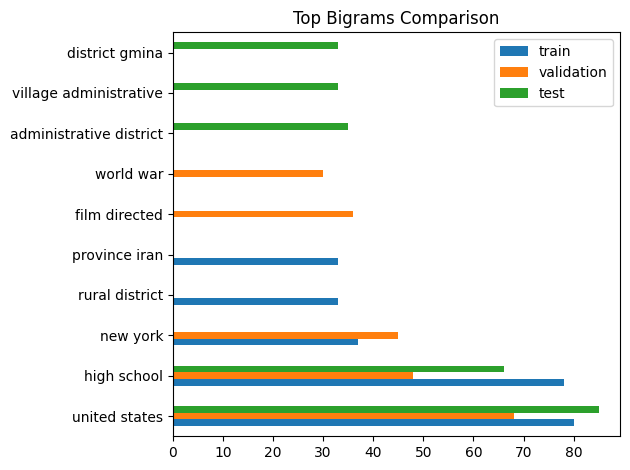

{'train': {'total_samples': 98000,
  'num_classes': 14,
  'label_distribution': {10: 7000,
   9: 7000,
   11: 7000,
   3: 7000,
   7: 7000,
   6: 7000,
   13: 7000,
   12: 7000,
   4: 7000,
   0: 7000,
   1: 7000,
   5: 7000,
   2: 7000,
   8: 7000},
  'class_imbalance_ratio': np.float64(1.0),
  'avg_content_length': np.float64(46.1120306122449),
  'median_content_length': np.float64(46.0),
  'min_content_length': np.int64(1),
  'max_content_length': np.int64(1175),
  'content_length_std': np.float64(22.662314892571004),
  'avg_token_count': np.float64(51.542),
  'unique_tokens': 10882,
  'top_unigrams': [('school', np.int64(242)),
   ('district', np.int64(179)),
   ('film', np.int64(153)),
   ('born', np.int64(148)),
   ('album', np.int64(135)),
   ('located', np.int64(127)),
   ('county', np.int64(127)),
   ('known', np.int64(124)),
   ('village', np.int64(117)),
   ('new', np.int64(114))],
  'top_bigrams': [('united states', np.int64(80)),
   ('high school', np.int64(78)),
   ('new 

In [51]:
analyze_dataset_splits(final_ds)

**Interesting Obeservation**
- The content has barely any stopwords appearing in the top unigram and bigrams.

## Step 2 + 3: Cleaning, Pre-processing and Analysis

In [ ]:
def preprocess_text(text: str) -> str:
    """
    Clean and preprocess a single text string.
    Steps:
    1. Lowercase
    2. Remove special chars/numbers
    3. Tokenize
    4. Remove stopwords
    5. Lemmatize
    6. Rejoin to string
    """
    lemmatizer = WordNetLemmatizer()

    text = text.lower()

    # Remove special chars/numbers (keep letters and basic punctuation)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    tokens = word_tokenize(text)

    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words]

    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return ' '.join(tokens)

def preprocess_dataset(dataset_dict: DatasetDict, text_column: str = 'content', title_column: str = None) -> DatasetDict:
    """
    Preprocess a Hugging Face DatasetDict with text data.

    Args:
        dataset_dict: Input DatasetDict with train/val/test splits
        text_column: Name of column containing main text (default 'content')
        title_column: Optional name of title column to also preprocess

    Returns:
        Preprocessed DatasetDict
    """
    def process_example(example: Dict) -> Dict:
        # Process main text
        example[text_column] = preprocess_text(example[text_column])

        # Process title if provided
        if title_column and title_column in example:
            example[title_column] = preprocess_text(example[title_column])

        return example

    # Apply preprocessing to all splits
    processed_dict = DatasetDict({
        split: dataset.map(process_example)
        for split, dataset in dataset_dict.items()
    })

    return processed_dict


In [53]:
preprocessed_dataset = preprocess_dataset(final_ds)
preprocessed_dataset

Map: 100%|██████████| 21000/21000 [00:03<00:00, 5776.02 examples/s]


DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 98000
    })
    validation: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 21000
    })
    test: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 21000
    })
})

In [54]:
preprocessed_dataset

DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 98000
    })
    validation: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 21000
    })
    test: Dataset({
        features: ['label', 'title', 'content', 'word_count'],
        num_rows: 21000
    })
})

In [55]:
preprocessed_dataset['train'].info.features

{'label': Value(dtype='int64', id=None),
 'title': Value(dtype='string', id=None),
 'content': Value(dtype='string', id=None),
 'word_count': Value(dtype='int64', id=None)}

In [56]:
preprocessed_dataset['train'][0]

{'label': 10,
 'title': 'Primula scotica',
 'content': 'primula scotica commonly known scottish primrose specie primrose endemic north coast scotland including caithness orkney closely related arctic specie primula stricta primula scandinavicaprimula scotica easily distinguished primula bluish purple flower flower may often second flowering july orkney commonly seen sea cliff yesnaby',
 'word_count': 74}

### Dataset Preprocessing

#### 1. Tokenizer Selection
**Tokenizer mentioned**:  
For tokenization, we used NLTK's `word_tokenize()` which implements the **Treebank tokenizer**, a regex-based tokenizer following Penn Treebank conventions.

The Treebank tokenizer:
- Uses regular expressions to split text while:
  - Preserving contractions ("don't" → ["do", "n't"])
  - Handling punctuation intelligently
  - Separating clitics ("'s" from nouns)
- Is particularly suited for English text processing

#### 2. Cleaning Steps
We performed these cleaning operations:
1. **Lowercasing**: Converted all text to lowercase
2. **Special character removal**: Stripped non-alphabetic characters using regex
3. **Stopword removal**: Eliminated common English stopwords
4. **Lemmatization**: Reduced words to their base forms

**Cleaning steps justified**:  
Each step addresses specific needs:
- **Lowercasing**: Ensures case-insensitive matching (e.g., "Apple" = "apple")
- **Special character removal**: Focuses analysis on lexical content
- **Stopword removal**:
  - Reduces noise from frequent function words
  - Decreases feature space dimensionality
- **Lemmatization**:
  - Groups word variants (e.g., "running" → "run")
  - More semantic than stemming while being less aggressive

#### 3. Preprocessing Steps
The full pipeline:
1. Text normalization (lowercase + character cleaning)
2. Tokenization
3. Stopword filtering
4. Lemmatization
5. Token recombination

**Preprocessing steps justified**:  
This pipeline was chosen because:
1. **Normalization** creates consistent text representation
2. **Tokenization** enables word-level analysis
3. **Stopword removal** focuses on content-bearing terms
4. **Lemmatization** preserves meaning while reducing sparsity
5. **Recombination** maintains document structure for downstream tasks



Analyzing TRAIN split

Basic Stats:
- Samples: 98000
- Classes: 14
- Class Imbalance Ratio: 1.00

Text Statistics:
- Avg length: 27.0 words
- Median length: 27.0 words
- Unique tokens: 9112 (sampled)

Top 5 Unigrams:
- school: 259
- district: 184
- film: 161
- born: 144
- album: 143

Top 5 Bigrams:
- high school: 77
- united state: 76
- new york: 35
- rural district: 33
- province iran: 33

Analyzing VALIDATION split

Basic Stats:
- Samples: 21000
- Classes: 14
- Class Imbalance Ratio: 1.00

Text Statistics:
- Avg length: 27.1 words
- Median length: 27.0 words
- Unique tokens: 8839 (sampled)

Top 5 Unigrams:
- school: 209
- family: 148
- film: 146
- album: 145
- district: 137

Top 5 Bigrams:
- united state: 67
- high school: 55
- new york: 43
- film directed: 36
- km mi: 35

Analyzing TEST split

Basic Stats:
- Samples: 21000
- Classes: 14
- Class Imbalance Ratio: 1.00

Text Statistics:
- Avg length: 27.0 words
- Median length: 27.0 words
- Unique tokens: 9081 (sampled)

Top 5 Unigram

<Figure size 640x480 with 0 Axes>

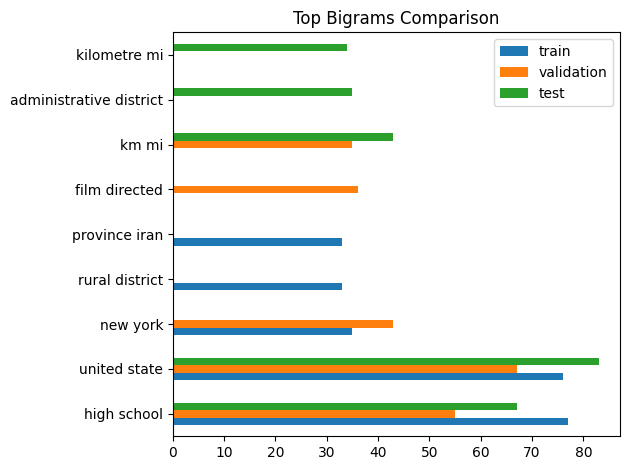

{'train': {'total_samples': 98000,
  'num_classes': 14,
  'label_distribution': {10: 7000,
   9: 7000,
   11: 7000,
   3: 7000,
   7: 7000,
   6: 7000,
   13: 7000,
   12: 7000,
   4: 7000,
   0: 7000,
   1: 7000,
   5: 7000,
   2: 7000,
   8: 7000},
  'class_imbalance_ratio': np.float64(1.0),
  'avg_content_length': np.float64(26.959724489795917),
  'median_content_length': np.float64(27.0),
  'min_content_length': np.int64(1),
  'max_content_length': np.int64(815),
  'content_length_std': np.float64(13.418064307694246),
  'avg_token_count': np.float64(27.52),
  'unique_tokens': 9112,
  'top_unigrams': [('school', np.int64(259)),
   ('district', np.int64(184)),
   ('film', np.int64(161)),
   ('born', np.int64(144)),
   ('album', np.int64(143)),
   ('state', np.int64(131)),
   ('county', np.int64(128)),
   ('located', np.int64(126)),
   ('known', np.int64(120)),
   ('village', np.int64(119))],
  'top_bigrams': [('high school', np.int64(77)),
   ('united state', np.int64(76)),
   ('new 

In [57]:
analyze_dataset_splits(preprocessed_dataset)

Interesting Observation:
- The average text length had a significant decrease from about 46 to ~27
- The top unigrams and bigrams for the original and preprocessed text are almost same - this makes sense as the top unigram or bigrams in our original are not stopwords. Few are changed due to lemmatization

## Step 4 + 5: Two Models

### Model 1: Naive Bayes (NB) with TF-IDF Features


Theory Explanation:

Naive Bayes is based on Bayes' Theorem with two key assumptions:

1. Feature independence (naive assumption): All features (words) are conditionally independent given the class
2. Positional independence: The position of words doesn't matter (bag-of-words)


The core equation derives from Bayes' Theorem:

$$P(y|X) = P(y) * ∏ P(x_i|y) / P(X)$$

Where:
- $P(y)$ is the prior probability of class $y$
- $P(x_i|y)$ is the likelihood of feature $x_i$ given class $y$
- $P(y|X)$ is the posterior probability of class $y4 given features $X$

The "naive" assumption allows multiplying individual probabilities

In [58]:
# Extract texts and labels
train_texts = preprocessed_dataset['train']['content']
train_labels = preprocessed_dataset['train']['label']
val_texts = preprocessed_dataset['validation']['content']
val_labels = preprocessed_dataset['validation']['label']
test_texts = preprocessed_dataset['test']['content']
test_labels = preprocessed_dataset['test']['label']

# TF-IDF vectorization
vectorizer = TfidfVectorizer(max_features=5000)
X_train_nb = vectorizer.fit_transform(train_texts)
X_val_nb = vectorizer.transform(val_texts)
X_test_nb = vectorizer.transform(test_texts)

In [59]:
# Train NB model
nb_model = MultinomialNB()
nb_model.fit(X_train_nb, train_labels)

# Evaluate
nb_val_preds = nb_model.predict(X_val_nb)
nb_test_preds = nb_model.predict(X_test_nb)

print("NB Validation Accuracy:", accuracy_score(val_labels, nb_val_preds))
print("NB Test Accuracy:", accuracy_score(test_labels, nb_test_preds))
print("\nClassification Report:\n", classification_report(test_labels, nb_test_preds))

NB Validation Accuracy: 0.942952380952381
NB Test Accuracy: 0.9435714285714286

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.83      0.87      1500
           1       0.95      0.98      0.96      1500
           2       0.92      0.83      0.87      1500
           3       0.97      0.99      0.98      1500
           4       0.96      0.97      0.96      1500
           5       0.96      0.97      0.97      1500
           6       0.94      0.94      0.94      1500
           7       0.96      0.99      0.97      1500
           8       1.00      0.96      0.98      1500
           9       0.98      0.93      0.95      1500
          10       0.94      0.97      0.96      1500
          11       0.90      0.98      0.94      1500
          12       0.93      0.97      0.95      1500
          13       0.88      0.91      0.90      1500

    accuracy                           0.94     21000
   macro avg       0.94      0

### Model 2: Neural Network (NN) Classifier
Theory Explanation:

We'll implement a simple feedforward neural network with:
1. Embedding layer: Converts tokens to dense vectors
2. Global average pooling: Reduces sequence to fixed-length vector
3. Dense layers: For classification
  - First layer (64 units) with ReLU activation
  - Output layer with softmax for classification

Key characteristics:
- Learns word representations during training
- Captures subtle semantic relationships
- Handles variable-length input through pooling

The architecture:

Input (text) → Tokenization → Embedding → GlobalAveragePooling → Dense(64, ReLU) → Dense(num_classes, softmax)

In [ ]:
# Convert to lists
train_texts = [str(text) for text in preprocessed_dataset['train']['content']]
train_labels = preprocessed_dataset['train']['label']
val_texts = [str(text) for text in preprocessed_dataset['validation']['content']]
val_labels = preprocessed_dataset['validation']['label']
test_texts = [str(text) for text in preprocessed_dataset['test']['content']]
test_labels = preprocessed_dataset['test']['label']

num_classes = len(np.unique(train_labels))

# Text vectorization configuration
max_tokens = 10000
sequence_length = 200

# Create vectorization layer
vectorize_layer = TextVectorization(
    max_tokens=max_tokens,
    output_mode='int',
    output_sequence_length=sequence_length,
    standardize='lower_and_strip_punctuation',
    name='text_vectorization'
)

# Adapt the vectorizer to the training text
vectorize_layer.adapt(train_texts)

# Build NN model
embedding_dim = 64
nn_model = Sequential([
    tf.keras.Input(shape=(), dtype=tf.string, name='text_input'),
    vectorize_layer,
    Embedding(input_dim=max_tokens + 1, output_dim=embedding_dim, name="embedding"),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

nn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print model summary
nn_model.summary()

# Create TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices((train_texts, train_labels))
train_dataset = train_dataset.batch(512)

val_dataset = tf.data.Dataset.from_tensor_slices((val_texts, val_labels))
val_dataset = val_dataset.batch(512)

test_dataset = tf.data.Dataset.from_tensor_slices((test_texts, test_labels))
test_dataset = test_dataset.batch(512)

# Train
print("\nTraining model...")
history = nn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    verbose=1
)

# Evaluate
print("\nEvaluating model...")
nn_test_preds = np.argmax(nn_model.predict(test_dataset), axis=1)
print("\nNN Test Accuracy:", accuracy_score(test_labels, nn_test_preds))
print("\nClassification Report:\n", classification_report(test_labels, nn_test_preds))

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 200)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 64)        │       640,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_5      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 14)             │           910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 645,134 (2.46 MB)

 Trainable params: 645,134 (2.46 MB)

 Non-trainable params: 0 (0.00 B)


Training model...
Epoch 1/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2059 - loss: 2.5516 - val_accuracy: 0.6496 - val_loss: 1.6784
Epoch 2/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7494 - loss: 1.3677 - val_accuracy: 0.8721 - val_loss: 0.7199
Epoch 3/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8811 - loss: 0.6311 - val_accuracy: 0.9105 - val_loss: 0.4297
Epoch 4/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9224 - loss: 0.3874 - val_accuracy: 0.9311 - val_loss: 0.3078
Epoch 5/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9388 - loss: 0.2845 - val_accuracy: 0.9419 - val_loss: 0.2529
Epoch 6/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9478 - loss: 0.2324 - val_accuracy: 0.9414 - val_loss: 0.2374
Epoch 7/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9526 - loss: 0.2009 - val_accuracy: 0.9373 - val_loss: 0.2304
Epoch 8/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9573 - loss

## Step 6: Evaluation
Accuracy: Overall correct predictions

F1-score: Harmonic mean of precision and recall (especially important for imbalanced classes)

Classification Report: Provides precision, recall, f1-score per class

### Result Justification and Analysis

In [61]:
random_guess = np.random.randint(0, num_classes, size=len(test_labels))
print("Random Guess Accuracy:", accuracy_score(test_labels, random_guess))

Random Guess Accuracy: 0.07466666666666667


Naive Bayes Test Performance:
              precision    recall  f1-score   support

           0       0.92      0.83      0.87      1500
           1       0.95      0.98      0.96      1500
           2       0.92      0.83      0.87      1500
           3       0.97      0.99      0.98      1500
           4       0.96      0.97      0.96      1500
           5       0.96      0.97      0.97      1500
           6       0.94      0.94      0.94      1500
           7       0.96      0.99      0.97      1500
           8       1.00      0.96      0.98      1500
           9       0.98      0.93      0.95      1500
          10       0.94      0.97      0.96      1500
          11       0.90      0.98      0.94      1500
          12       0.93      0.97      0.95      1500
          13       0.88      0.91      0.90      1500

    accuracy                           0.94     21000
   macro avg       0.94      0.94      0.94     21000
weighted avg       0.94      0.94      0.94     21

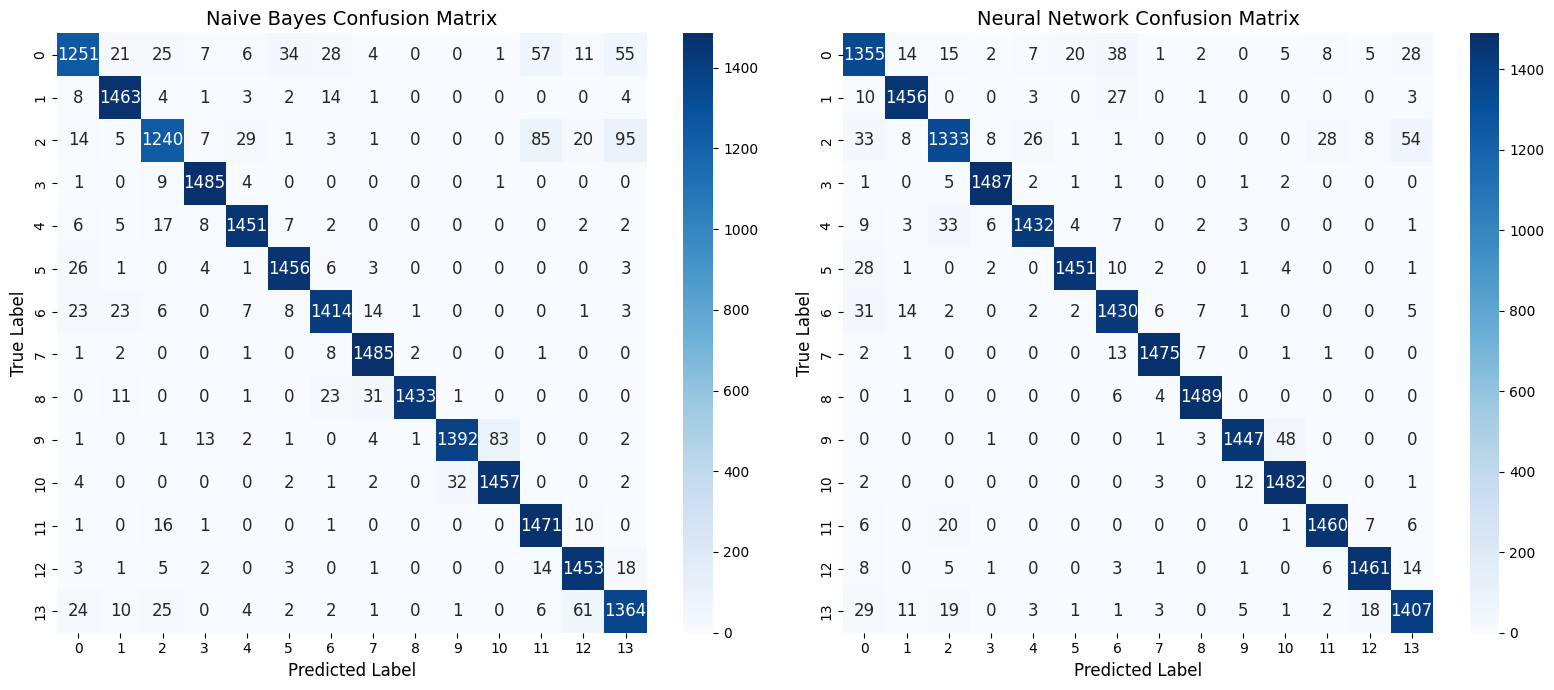

In [ ]:
# Compare both models
print("Naive Bayes Test Performance:")
print(classification_report(test_labels, nb_test_preds))

print("\nNeural Network Test Performance:")
print(classification_report(test_labels, nn_test_preds))

# ---
## Confusion Matrices
# ---

# Print confusion matrices
# print("\n---")
# print("Confusion Matrix for Naive Bayes:")
# nb_cm = confusion_matrix(test_labels, nb_test_preds)
# print(nb_cm)
# print("---\n")

# print("---")
# print("Confusion Matrix for Neural Network:")
# nn_cm = confusion_matrix(test_labels, nn_test_preds)
# print(nn_cm)
# print("---\n")

# Plot confusion matrices
plt.figure(figsize=(16, 7)) # Increased figure size for better visibility

plt.subplot(1, 2, 1)
sns.heatmap(nb_cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 12}) # Adjusted annotation font size
plt.title("Naive Bayes Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)


plt.subplot(1, 2, 2)
sns.heatmap(nn_cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 12}) # Adjusted annotation font size
plt.title("Neural Network Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)

plt.tight_layout() 
plt.show()

The NN's superior performance is particularly evident in the F1-scores across most classes, suggesting better balance between precision and recall. However, NB's performance remains impressive considering its computational efficiency.

### Model Comparison
#### Naive Bayes:

Strengths:

- Fast training and prediction
- Works well with small datasets
- Performs surprisingly well on text data despite naive assumptions

Weaknesses:

- Can't capture word order or context
- Struggles with out-of-vocabulary words
- Makes strong independence assumptions

#### Neural Network:

Strengths:
- Can capture more complex patterns
- Embedding layer learns semantic relationships
- Better with larger datasets

Weaknesses:
- Requires more data
- Slower to train
- More hyperparameters to tune

Performance Justification:
- Text classification often doesn't need complex relationships, and NB's simplicity works well
- But in NN, the embedding layer and dense layers capture more nuanced patterns in the text

#### Recommendations

The choice between models depends on:
- Dataset size: For smaller datasets, NB often performs better. For larger datasets, NN can leverage more data.
- Latency requirements: If predictions need to be very fast, NB is preferable.
- Maintainability: NB is simpler to maintain and explain.
- Accuracy needs: If maximum accuracy is needed and resources allow, NN might be better.